<a href="https://colab.research.google.com/github/k8peevey-sys/ds2002-fa26/blob/main/Copy_of_2026_11_13_visualization_challenge_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

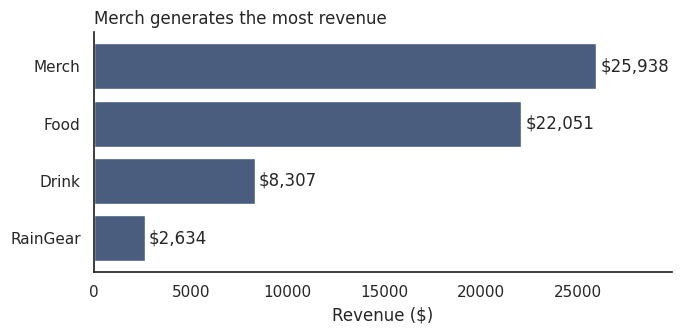

In [ ]:
# TODO
# Summing total revenue by category
cat_rev = df.groupby('category')['revenue'].sum().sort_values()

fig,ax = plt.subplots(figsize=(7,3.5))

#Creating horizonal bar chart
bars = ax.barh(cat_rev.index, cat_rev.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in cat_rev.values], padding=3)
#Need more room for labels
ax.set_xlim(0,cat_rev.max()*1.15)
finish(ax, f'{cat_rev.idxmax()} generates the most revenue', xlabel= 'Revenue ($)', ylabel='')
plt.show()

**Caption:** _Since, by the chart, merch makes the most revenue,it should be prioritized for marketing and research projects in order to maximize these numbers._

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

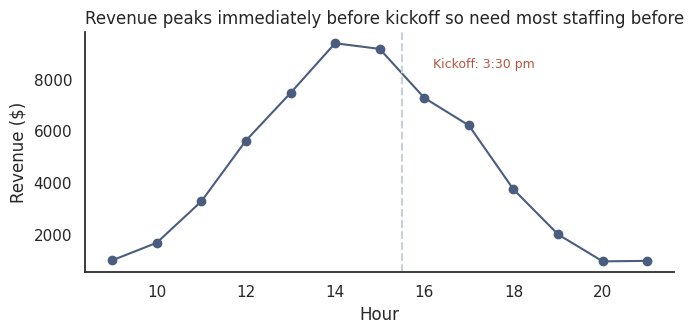

In [ ]:
from matplotlib.lines import lineStyles
from matplotlib.typing import MarkerType
# TODO
# Total revenue by hour
hourly_rev = df.groupby('hour')['revenue'].sum()

fig,ax = plt.subplots(figsize=(7,3.5))

#Creating line chart
ax.plot(hourly_rev.index, hourly_rev.values, marker='o', color=BLUE)
ax.axvline(15.5, linestyle='--',color=GRAY)
ax.annotate('Kickoff: 3:30 pm', xy=(15.5, hourly_rev.max()*.75), xytext=(16.2,hourly_rev.max()*.9),fontsize=9,color=RUST)

finish(ax, 'Revenue peaks immediately before kickoff so need most staffing before', xlabel='Hour', ylabel='Revenue ($)')
plt.show()

**Caption:** _Chart indicates that staff levels should be highest in the few hours leading up to kickoff as that is when revenue peaks and will require the most staff._

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

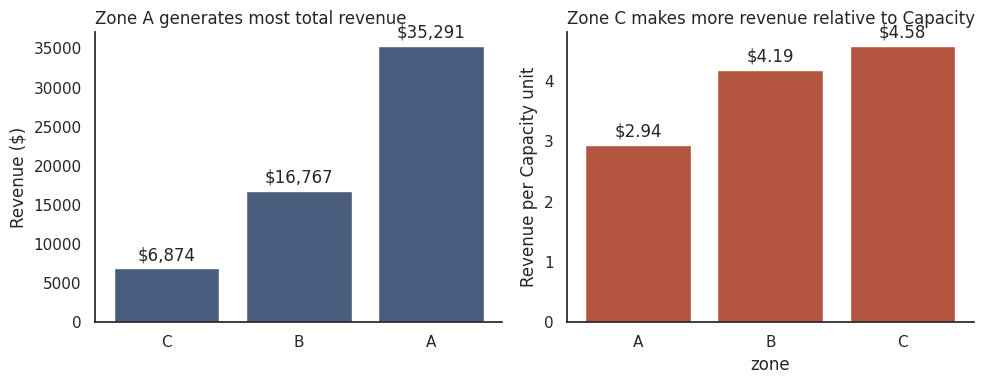

In [ ]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity
#Total revenue per zone, normalized by capacity
zone_rev = df.groupby('zone')['revenue'].sum()
rev_per_cap = pd.Series({z: zone_rev[z] / zone_capacity[z] for z in zone_rev.index})

fig,ax = plt.subplots(1,2, figsize=(10,4))

#Left panel: raw revenue
raw_sorted = zone_rev.sort_values()

left_bar = ax[0].bar(raw_sorted.index, raw_sorted.values, color=BLUE)
ax[0].bar_label(left_bar, labels=[f'${v:,.0f}' for v in raw_sorted.values], padding=3)
finish(ax[0], 'Zone A generates most total revenue', xlabel='', ylabel='Revenue ($)')

#Right panel: revenue per capacity
norm_sorted = rev_per_cap.sort_values()

right_bar = ax[1].bar(norm_sorted.index, norm_sorted.values, color=RUST)
ax[1].bar_label(right_bar, labels=[f'${v:,.2f}' for v in norm_sorted.values], padding=3)
finish(ax[1], 'Zone C makes more revenue relative to Capacity', xlabel='zone', ylabel='Revenue per Capacity unit')

plt.show()

**Caption, and which panel I would present:** _Zone A has the most revenue overall but Zone C is the best per unit of capacity. I would show the right panel to illustrate where more resources could be put into expanding an untaped avenue._

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

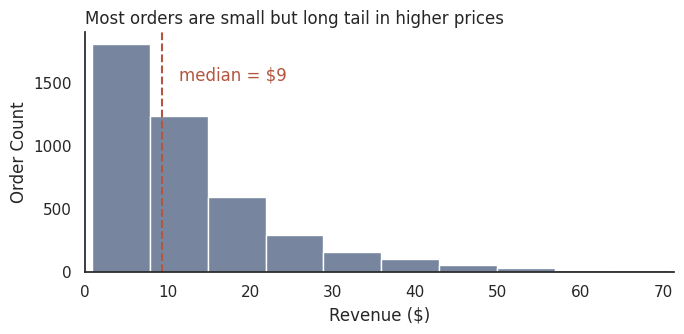

In [ ]:
# TODO
#Summary stats
median_rev = df['revenue'].median()
std_rev = df['revenue'].std()
p99_rev = df['revenue'].quantile(.99)

#Creating histogram

fig,ax = plt.subplots(figsize=(7,3.5))

#Making the histogram
sns.histplot(data=df, x='revenue', bins=30, color=BLUE, ax=ax)
ax.axvline(median_rev, linestyle='--', color=RUST)
ax.set_xlim(0,p99_rev*1.1)
ax.text(median_rev +2, ax.get_ylim()[1]*.8, f'median = ${median_rev:.0f}',color=RUST)
finish(ax, 'Most orders are small but long tail in higher prices', xlabel='Revenue ($)', ylabel='Order Count')

plt.show()

**Caption:** _Most purchases are small with a few high priced purchases contributing a lot to revenue, since the histogram is heavily skewed._

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

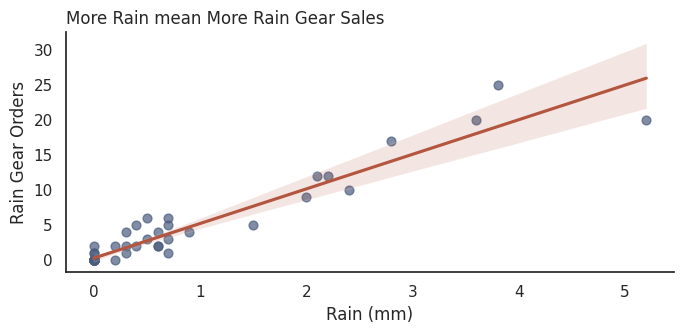

In [ ]:
# TODO
#I'm going to do a scatter plot to show relationship between rain and rain gear
#First I'm comparing rain and rain gear
hourly_rain = df.groupby(['game','hour']).agg(rain_mm=('rain_mm','first'),raingear_orders=('category', lambda s: (s=='RainGear').sum())).reset_index()

fig, ax = plt.subplots(figsize=(7, 3.5))

#Scatter plot and trend lines
sns.regplot(data=hourly_rain, x='rain_mm', y='raingear_orders', ax=ax, scatter_kws={'s':40,'alpha':.7, 'color':BLUE}, line_kws={'color':RUST} )
finish(ax, 'More Rain mean More Rain Gear Sales', xlabel='Rain (mm)', ylabel='Rain Gear Orders')
plt.show()

**Caption:** _Raingear purchases increase as rainfall increases. So, could use weather forecasts to anticipate demand and stock well. _

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [ ]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 5,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 5,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             5/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      5/6  [ok]

average: 5.6/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 3 changed my mind the most about the revenue. Since it shows that even though Zone A appears to be the best revenue zone, Zone C is the best relative to its capacity, I changed my mind about trusting just the raw revenue comparison.

b) The raw revenue panel is correct when thincking about where the most money is coming from and where most sales are happening. The revenue by capacity panel is the correct view when thinking about how to expand operations or relocate resources to improve sales in areas that may be lacking capcity but have good numbers for where they are.